In [2]:
from pathlib import Path
from PIL import Image
import matplotlib.pyplot as plt

# Dataset paths
DATA_DIR = Path("../data")

TRAIN_DIR = DATA_DIR / "train"
VAL_DIR = DATA_DIR / "val"
TEST_DIR = DATA_DIR / "test"

print("Train:", TRAIN_DIR)
print("Validation:", VAL_DIR)
print("Test:", TEST_DIR)

print("\nEDA environment ready.")

Train: ..\data\train
Validation: ..\data\val
Test: ..\data\test

EDA environment ready.


In [3]:
from collections import Counter

# Count images in each class
class_counts = {}

for class_dir in sorted(TRAIN_DIR.iterdir()):
    if class_dir.is_dir():
        image_count = len([
            file for file in class_dir.iterdir()
            if file.suffix.lower() in {".jpg", ".jpeg", ".png"}
        ])
        class_counts[class_dir.name] = image_count

# Display counts
for class_name, count in class_counts.items():
    print(f"{class_name}: {count}")

Corn___Cercospora_leaf_spot Gray_leaf_spot: 359
Corn___Common_rust: 834
Corn___healthy: 813
Corn___Northern_Leaf_Blight: 689
Potato___Early_blight: 700
Potato___healthy: 106
Potato___Late_blight: 700
Tomato___Bacterial_spot: 1488
Tomato___Early_blight: 700
Tomato___healthy: 1113
Tomato___Late_blight: 1336
Tomato___Leaf_Mold: 666
Tomato___Septoria_leaf_spot: 1239
Tomato___Target_Spot: 982
Tomato___Tomato_Yellow_Leaf_Curl_Virus: 3749


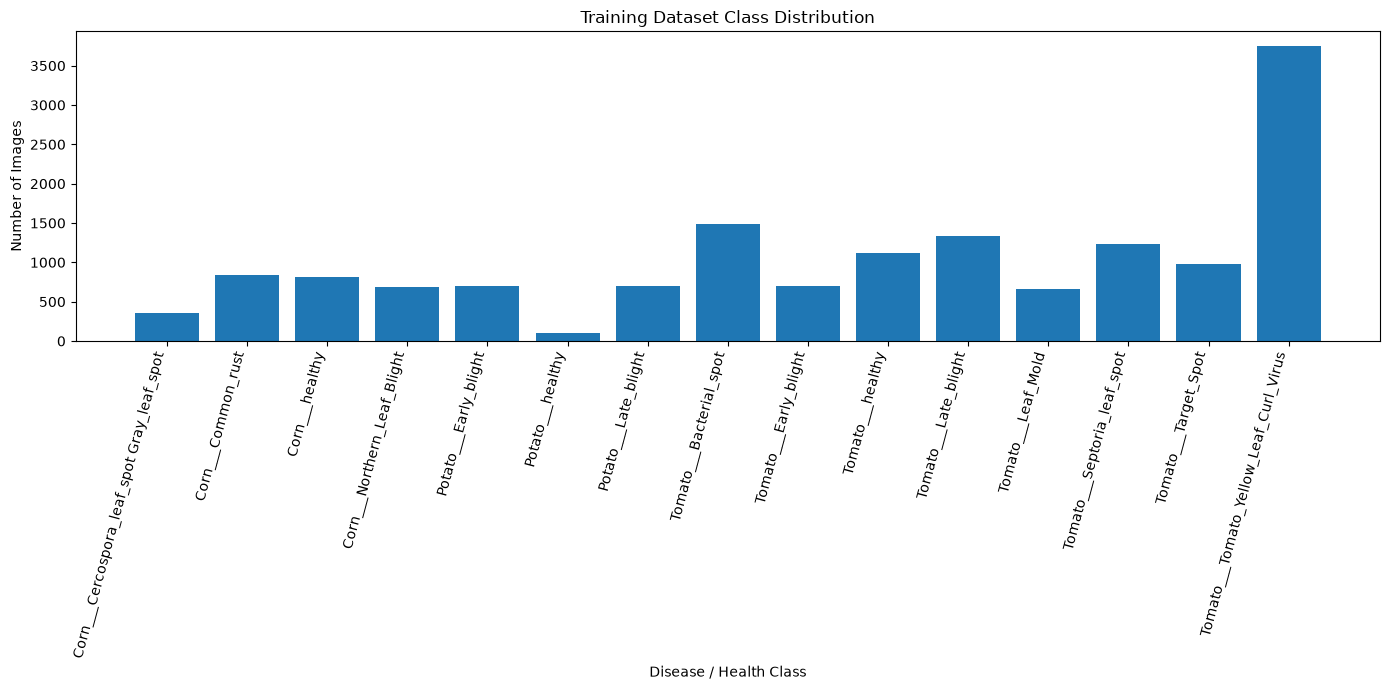

In [4]:
# Plot training class distribution

classes = list(class_counts.keys())
counts = list(class_counts.values())

plt.figure(figsize=(14, 7))

plt.bar(classes, counts)

plt.title("Training Dataset Class Distribution")
plt.xlabel("Disease / Health Class")
plt.ylabel("Number of Images")

plt.xticks(rotation=75, ha="right")

plt.tight_layout()
plt.show()

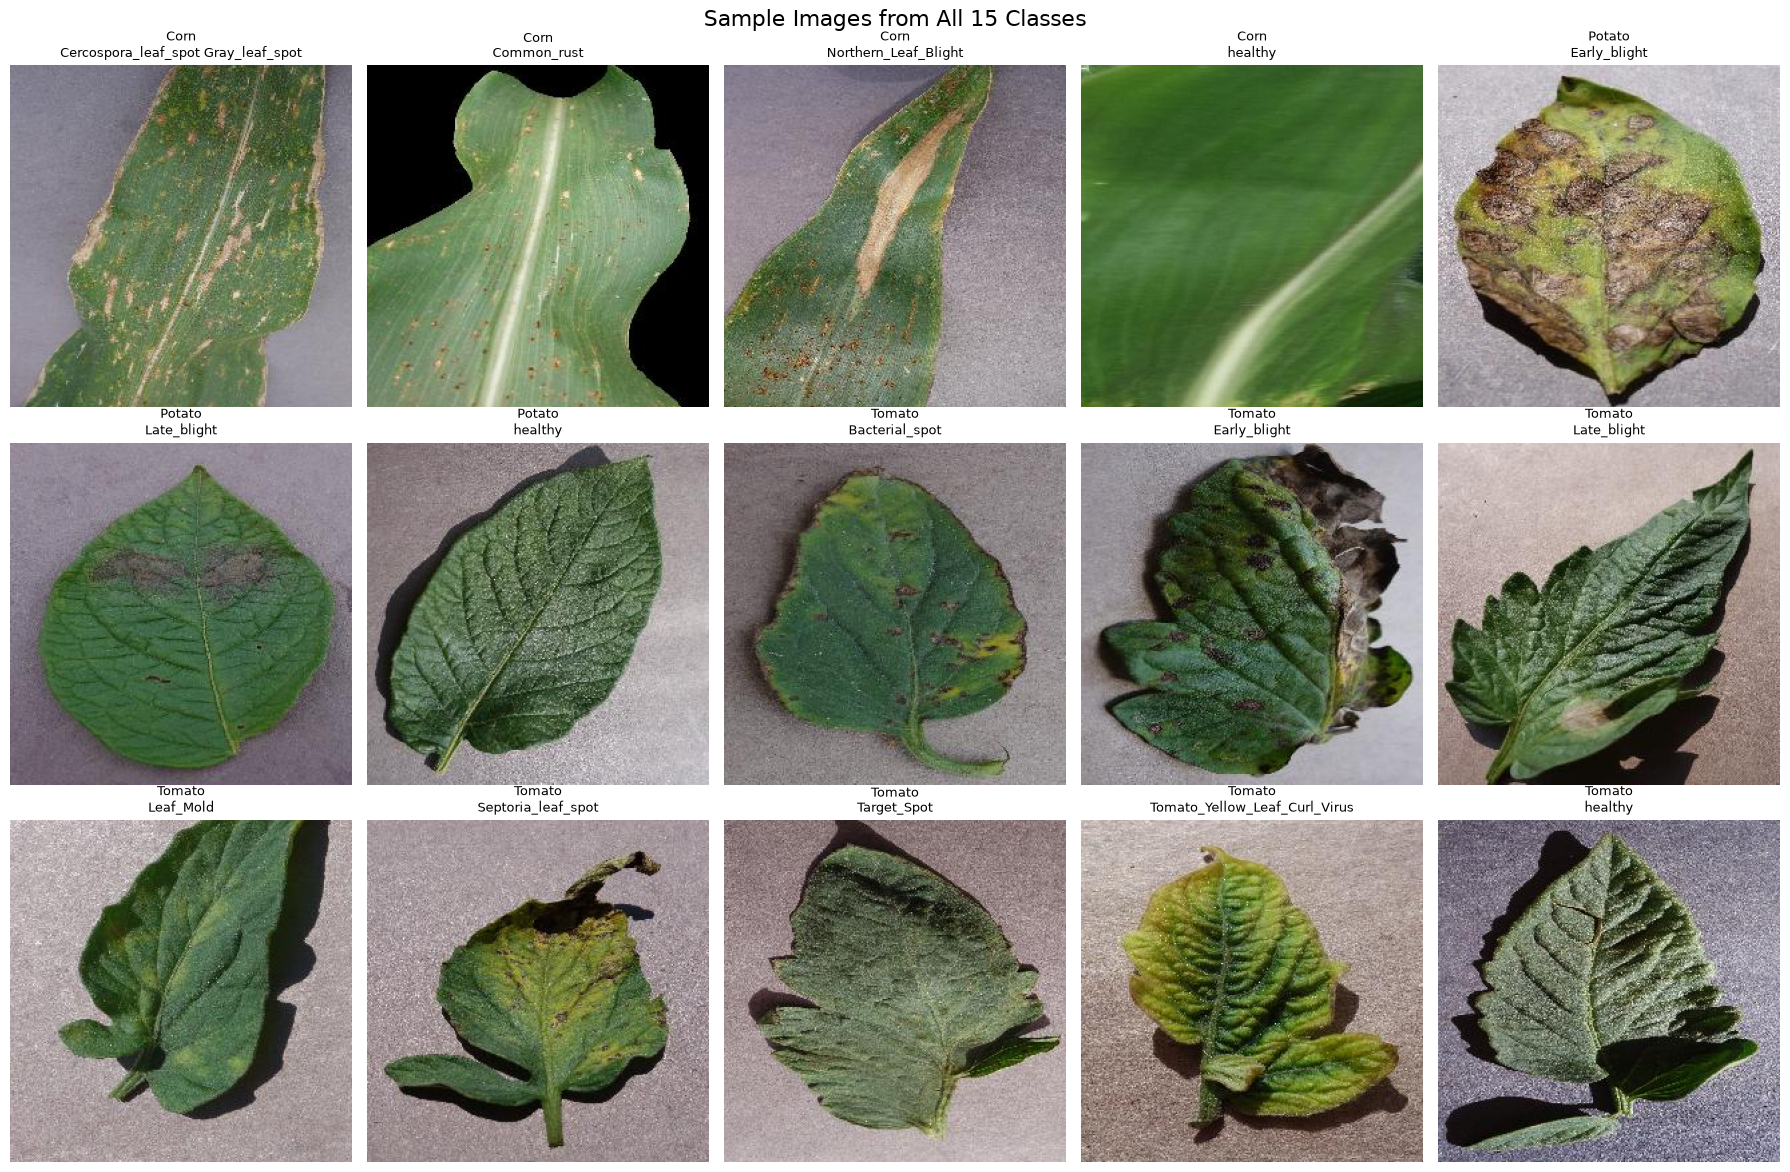

In [5]:
import random
import matplotlib.pyplot as plt
from PIL import Image

# Select one random image from each class
random.seed(42)

classes = sorted([
    folder.name
    for folder in TRAIN_DIR.iterdir()
    if folder.is_dir()
])

fig, axes = plt.subplots(3, 5, figsize=(18, 12))

for ax, class_name in zip(axes.flat, classes):

    class_dir = TRAIN_DIR / class_name

    images = [
        file for file in class_dir.iterdir()
        if file.suffix.lower() in {".jpg", ".jpeg", ".png"}
    ]

    image_path = random.choice(images)

    image = Image.open(image_path)

    ax.imshow(image)
    ax.set_title(class_name.replace("___", "\n"), fontsize=9)
    ax.axis("off")

plt.suptitle("Sample Images from All 15 Classes", fontsize=16)

plt.tight_layout()
plt.show()

In [6]:
# Check image dimensions in the training dataset

image_sizes = Counter()

for class_dir in TRAIN_DIR.iterdir():
    if class_dir.is_dir():
        for image_path in class_dir.iterdir():
            if image_path.suffix.lower() in {".jpg", ".jpeg", ".png"}:
                try:
                    with Image.open(image_path) as img:
                        image_sizes[img.size] += 1
                except Exception:
                    pass

print(f"Number of unique image sizes: {len(image_sizes)}")

print("\nMost common image sizes:")
for size, count in image_sizes.most_common(10):
    print(f"{size}: {count} images")

Number of unique image sizes: 1

Most common image sizes:
(256, 256): 15474 images


In [7]:
# Check for corrupted or unreadable images

valid_extensions = {".jpg", ".jpeg", ".png"}

total_images = 0
corrupted_images = []

for class_dir in TRAIN_DIR.iterdir():
    if class_dir.is_dir():
        for image_path in class_dir.iterdir():

            if image_path.suffix.lower() in valid_extensions:
                total_images += 1

                try:
                    with Image.open(image_path) as img:
                        img.verify()
                except Exception:
                    corrupted_images.append(str(image_path))

print("Total images checked:", total_images)
print("Corrupted images:", len(corrupted_images))

if corrupted_images:
    print("\nCorrupted image examples:")
    for path in corrupted_images[:10]:
        print(path)
else:
    print("All images are readable.")

Total images checked: 15474
Corrupted images: 0
All images are readable.


In [8]:
# Compare train, validation and test counts for every class

split_dirs = {
    "Train": TRAIN_DIR,
    "Validation": VAL_DIR,
    "Test": TEST_DIR
}

distribution = {}

for class_name in sorted(class_counts.keys()):
    distribution[class_name] = {}

    for split_name, split_dir in split_dirs.items():
        class_dir = split_dir / class_name

        count = len([
            file for file in class_dir.iterdir()
            if file.suffix.lower() in {".jpg", ".jpeg", ".png"}
        ])

        distribution[class_name][split_name] = count


# Display table
import pandas as pd

distribution_df = pd.DataFrame.from_dict(
    distribution,
    orient="index"
)

distribution_df["Total"] = distribution_df.sum(axis=1)

distribution_df

,Train,Validation,Test,Total
Corn___Cercospora_leaf_spot Gray_leaf_spot,359,76,78,513
Corn___Common_rust,834,178,180,1192
Corn___Northern_Leaf_Blight,689,147,149,985
Corn___healthy,813,174,175,1162
Potato___Early_blight,700,150,150,1000
Potato___Late_blight,700,150,150,1000
Potato___healthy,106,22,24,152
Tomato___Bacterial_spot,1488,319,320,2127
Tomato___Early_blight,700,150,150,1000
Tomato___Late_blight,1336,286,287,1909


In [1]:
import sys

print(sys.executable)
print(sys.version)

c:\Agro Care Ai\Agro Care AI\.venv\Scripts\python.exe
3.11.15 (main, Jun 11 2026, 04:59:07) [MSC v.1944 64 bit (AMD64)]
